In [3]:
!unzip /content/mitdb.zip

Archive:  /content/mitdb.zip
   creating: mitdb/
  inflating: mitdb/209.atr           
  inflating: mitdb/208.dat           
  inflating: mitdb/109.hea           
  inflating: mitdb/117.dat           
  inflating: mitdb/105.xws           
  inflating: mitdb/233.atr           
  inflating: mitdb/220.xws           
  inflating: mitdb/222.atr           
  inflating: mitdb/201.xws           
  inflating: mitdb/101.atr           
  inflating: mitdb/234.dat           
  inflating: mitdb/112.dat           
  inflating: mitdb/215.atr           
  inflating: mitdb/116.atr           
  inflating: mitdb/107.dat           
  inflating: mitdb/106.xws           
  inflating: mitdb/115.dat           
  inflating: mitdb/RECORDS           
  inflating: mitdb/231.xws           
  inflating: mitdb/217.dat           
  inflating: mitdb/213.atr           
  inflating: mitdb/233.xws           
  inflating: mitdb/223.xws           
  inflating: mitdb/117.hea           
  inflating: mitdb/119.hea           
 

In [4]:
!pip install wfdb tensorflow scikit-learn scipy pandas matplotlib seaborn pywavelets

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import wfdb
from scipy.signal import butter, filtfilt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("WFDB:", wfdb.__version__)

TensorFlow: 2.21.0
WFDB: 4.3.1


In [5]:
DATA_DIR = "mitdb"
os.makedirs(DATA_DIR, exist_ok=True)

record_list = wfdb.get_record_list("mitdb")

for rec in record_list:
    try:
        wfdb.dl_database(
            "mitdb",
            dl_dir=DATA_DIR,
            records=[rec]
        )
    except Exception as e:
        print(f"Could not download {rec}: {e}")

print("Number of records:", len(record_list))
print(record_list[:10])

Generating record list for: 100
Generating list of all files for: 100
Finished downloading files
Generating record list for: 101
Generating list of all files for: 101
Finished downloading files
Generating record list for: 102
Generating list of all files for: 102
Finished downloading files
Generating record list for: 103
Generating list of all files for: 103
Finished downloading files
Generating record list for: 104
Generating list of all files for: 104
Finished downloading files
Generating record list for: 105
Generating list of all files for: 105
Finished downloading files
Generating record list for: 106
Generating list of all files for: 106
Finished downloading files
Generating record list for: 107
Generating list of all files for: 107
Finished downloading files
Generating record list for: 108
Generating list of all files for: 108
Finished downloading files
Generating record list for: 109
Generating list of all files for: 109
Finished downloading files
Generating record list for: 11

Record: 100
Sampling frequency: 360
Channels: ['MLII', 'V5']
Signal shape: (650000, 2)


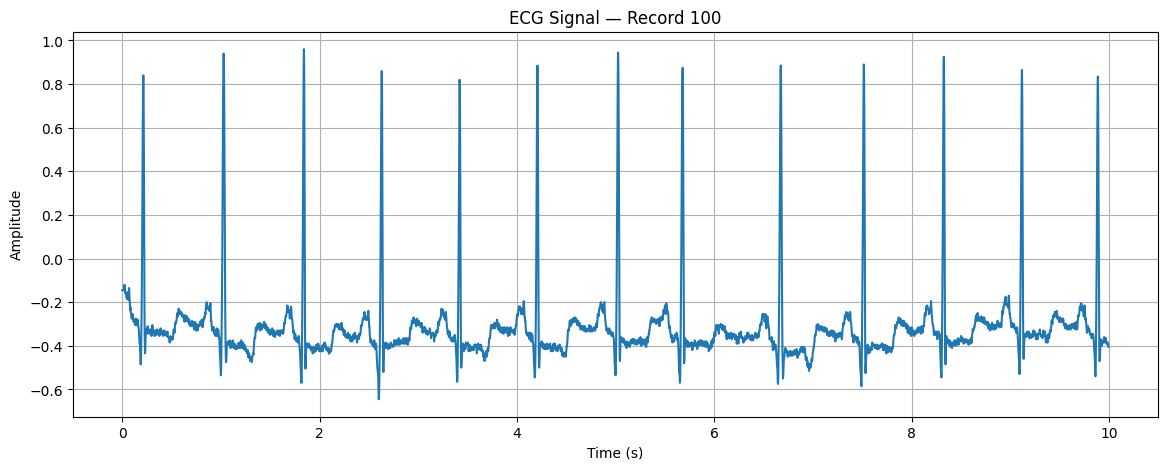

First annotation symbols: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


In [6]:
record_name = record_list[0]
record_path = os.path.join(DATA_DIR, record_name)

record = wfdb.rdrecord(record_path)
annotation = wfdb.rdann(record_path, "atr")

print("Record:", record_name)
print("Sampling frequency:", record.fs)
print("Channels:", record.sig_name)
print("Signal shape:", record.p_signal.shape)

seconds = 10
n_samples = int(seconds * record.fs)

plt.figure(figsize=(14, 5))
plt.plot(np.arange(n_samples) / record.fs, record.p_signal[:n_samples, 0])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"ECG Signal — Record {record_name}")
plt.grid(True)
plt.show()

print("First annotation symbols:", annotation.symbol[:50])

In [7]:
AAMI_MAP = {
    # N class
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",

    # S class
    "A": "S", "a": "S", "J": "S", "S": "S",

    # V class
    "V": "V", "E": "V",

    # F class
    "F": "F",

    # Q class
    "/": "Q", "f": "Q", "Q": "Q"
}

# Beat symbols used for extracting labeled beats.
BEAT_SYMBOLS = set(AAMI_MAP.keys())

def record_has_paced_beats(symbols):
    return "/" in symbols

print("AAMI mapping entries:", len(AAMI_MAP))

AAMI mapping entries: 15


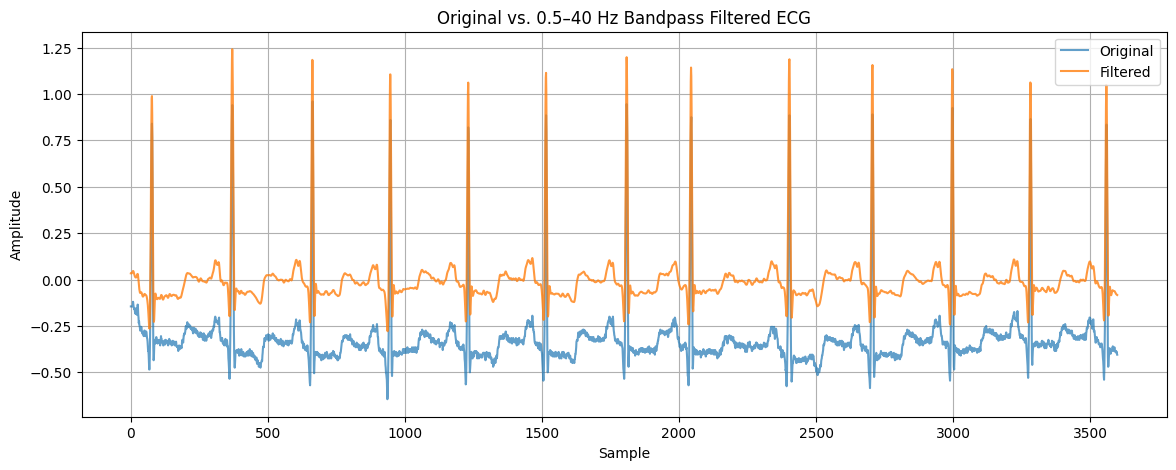

In [8]:
FS = 360
LOWCUT = 0.5
HIGHCUT = 40.0

def bandpass_filter(signal, fs=FS, lowcut=LOWCUT, highcut=HIGHCUT, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype="band")
    return filtfilt(b, a, signal)

filtered = bandpass_filter(record.p_signal[:, 0])

plt.figure(figsize=(14, 5))
plt.plot(record.p_signal[:n_samples, 0], label="Original", alpha=0.7)
plt.plot(filtered[:n_samples], label="Filtered", alpha=0.8)
plt.title("Original vs. 0.5–40 Hz Bandpass Filtered ECG")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
BEFORE = 100
AFTER = 150
WINDOW_SIZE = BEFORE + AFTER

def extract_beats_from_record(rec_name, data_dir=DATA_DIR):
    path = os.path.join(data_dir, rec_name)

    rec = wfdb.rdrecord(path)
    ann = wfdb.rdann(path, "atr")

    # Use first ECG channel.
    signal = rec.p_signal[:, 0].astype(np.float32)
    signal = bandpass_filter(signal, fs=rec.fs)

    if record_has_paced_beats(ann.symbol):
        return None

    beats = []
    labels = []

    for sample, symbol in zip(ann.sample, ann.symbol):
        if symbol not in BEAT_SYMBOLS:
            continue

        label = AAMI_MAP[symbol]

        start = sample - BEFORE
        end = sample + AFTER

        if start < 0 or end > len(signal):
            continue

        beat = signal[start:end].copy()

        beat = (beat - np.mean(beat)) / (np.std(beat) + 1e-8)

        beats.append(beat)
        labels.append(label)

    if not beats:
        return None

    return np.asarray(beats, dtype=np.float32), np.asarray(labels), rec_name

In [10]:
MAX_RECORDS = None

records_to_process = record_list if MAX_RECORDS is None else record_list[:MAX_RECORDS]

all_X = []
all_y = []
all_groups = []
skipped = []

for i, rec_name in enumerate(records_to_process, 1):
    try:
        result = extract_beats_from_record(rec_name)

        if result is None:
            skipped.append(rec_name)
            continue

        X_rec, y_rec, group_rec = result

        all_X.append(X_rec)
        all_y.append(y_rec)
        all_groups.extend([group_rec] * len(y_rec))

        print(f"[{i}/{len(records_to_process)}] {rec_name}: {len(y_rec)} beats")

    except Exception as e:
        skipped.append(rec_name)
        print(f"[{i}/{len(records_to_process)}] {rec_name}: ERROR -> {e}")

X = np.concatenate(all_X, axis=0)
y = np.concatenate(all_y, axis=0)
groups = np.asarray(all_groups)

print("\nDataset shape:", X.shape)
print("Labels:", pd.Series(y).value_counts().sort_index())
print("Skipped records:", skipped)

[1/48] 100: 2271 beats
[2/48] 101: 1864 beats
[4/48] 103: 2083 beats
[6/48] 105: 2572 beats
[7/48] 106: 2027 beats
[9/48] 108: 1762 beats
[10/48] 109: 2531 beats
[11/48] 111: 2124 beats
[12/48] 112: 2538 beats
[13/48] 113: 1794 beats
[14/48] 114: 1879 beats
[15/48] 115: 1952 beats
[16/48] 116: 2411 beats
[17/48] 117: 1534 beats
[18/48] 118: 2277 beats
[19/48] 119: 1987 beats
[20/48] 121: 1862 beats
[21/48] 122: 2474 beats
[22/48] 123: 1517 beats
[23/48] 124: 1618 beats
[24/48] 200: 2600 beats
[25/48] 201: 1963 beats
[26/48] 202: 2135 beats
[27/48] 203: 2979 beats
[28/48] 205: 2655 beats
[29/48] 207: 1859 beats
[30/48] 208: 2953 beats
[31/48] 209: 3004 beats
[32/48] 210: 2648 beats
[33/48] 212: 2747 beats
[34/48] 213: 3249 beats
[35/48] 214: 2260 beats
[36/48] 215: 3362 beats
[38/48] 219: 2154 beats
[39/48] 220: 2046 beats
[40/48] 221: 2427 beats
[41/48] 222: 2481 beats
[42/48] 223: 2605 beats
[43/48] 228: 2053 beats
[44/48] 230: 2255 beats
[45/48] 231: 1570 beats
[46/48] 232: 1780 beat

,Count
N,90086
S,2781
V,7008
F,802
Q,15


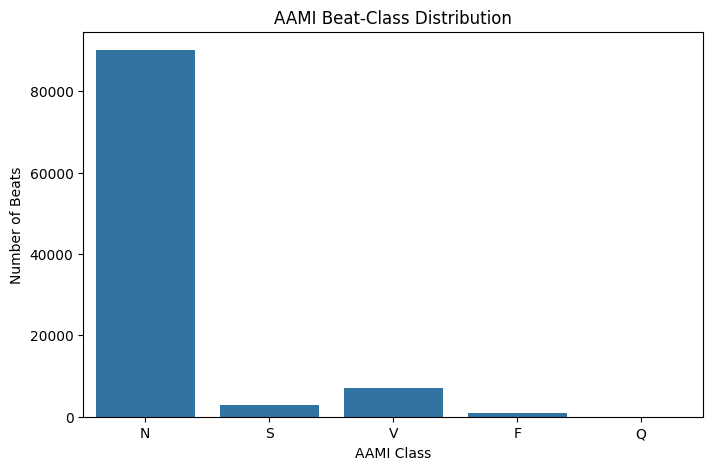

In [11]:
class_counts = pd.Series(y).value_counts().reindex(["N", "S", "V", "F", "Q"], fill_value=0)

display(class_counts.to_frame("Count"))

plt.figure(figsize=(8, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("AAMI Beat-Class Distribution")
plt.xlabel("AAMI Class")
plt.ylabel("Number of Beats")
plt.show()

In [12]:
unique_groups = np.unique(groups)

train_groups, temp_groups = train_test_split(
    unique_groups,
    test_size=0.30,
    random_state=SEED
)

val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    random_state=SEED
)

train_mask = np.isin(groups, train_groups)
val_mask = np.isin(groups, val_groups)
test_mask = np.isin(groups, test_groups)

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Train:", X_train.shape, len(y_train), "records:", len(train_groups))
print("Validation:", X_val.shape, len(y_val), "records:", len(val_groups))
print("Test:", X_test.shape, len(y_test), "records:", len(test_groups))

print("\nTrain class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Train: (68515, 250) 68515 records: 30
Validation: (15769, 250) 15769 records: 7
Test: (16408, 250) 16408 records: 7

Train class distribution:
F      769
N    60621
Q        8
S     1877
V     5240
Name: count, dtype: int64

Validation class distribution:
F       18
N    14628
S      338
V      785
Name: count, dtype: int64

Test class distribution:
F       15
N    14837
Q        7
S      566
V      983
Name: count, dtype: int64


In [13]:
CLASSES = ["N", "S", "V", "F", "Q"]
label_to_id = {label: i for i, label in enumerate(CLASSES)}
id_to_label = {i: label for label, i in label_to_id.items()}

y_train_int = np.array([label_to_id[v] for v in y_train])
y_val_int = np.array([label_to_id[v] for v in y_val])
y_test_int = np.array([label_to_id[v] for v in y_test])

present_classes = np.unique(y_train_int)
weights = compute_class_weight(
    class_weight="balanced",
    classes=present_classes,
    y=y_train_int
)
class_weight = {int(c): float(w) for c, w in zip(present_classes, weights)}

print("Class weights:", class_weight)

Class weights: {0: 0.2260437802081787, 1: 7.300479488545552, 2: 2.6150763358778626, 3: 17.81924577373212, 4: 1712.875}


In [14]:
X_train_rnn = X_train[..., np.newaxis]
X_val_rnn = X_val[..., np.newaxis]
X_test_rnn = X_test[..., np.newaxis]

print("RNN input shape:", X_train_rnn.shape)

RNN input shape: (68515, 250, 1)


In [15]:
NUM_CLASSES = len(CLASSES)

def build_model(kind, input_shape, units=64):
    model = Sequential([
        Input(shape=input_shape)
    ])

    if kind == "RNN":
        model.add(SimpleRNN(units))
    elif kind == "LSTM":
        model.add(LSTM(units))
    elif kind == "GRU":
        model.add(GRU(units))
    else:
        raise ValueError("kind must be RNN, LSTM, or GRU")

    model.add(Dropout(0.3))
    model.add(Dense(NUM_CLASSES, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

models = {
    "RNN": build_model("RNN", X_train_rnn.shape[1:]),
    "LSTM": build_model("LSTM", X_train_rnn.shape[1:]),
    "GRU": build_model("GRU", X_train_rnn.shape[1:])
}

for name, model in models.items():
    print("\n", name)
    model.summary()


 RNN


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,549 (17.77 KB)

 Trainable params: 4,549 (17.77 KB)

...

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,189 (51.52 KB)

 Trainable params: 13,189 (51.52 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
BATCH_SIZE = 128
EPOCHS = 30

histories = {}
trained_models = {}

for name, model in models.items():
    print(f"\n========== Training {name} ==========")

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train_rnn,
        y_train_int,
        validation_data=(X_val_rnn, y_val_int),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight,
        callbacks=[early_stop],
        verbose=1
    )

    histories[name] = history
    trained_models[name] = model


========== Training RNN ==========
Epoch 1/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 21s 26ms/step - accuracy: 0.2405 - loss: 1.5878 - val_accuracy: 0.0351 - val_loss: 1.5726
Epoch 2/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.2191 - loss: 1.6557 - val_accuracy: 0.3705 - val_loss: 1.4982
Epoch 3/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.2139 - loss: 1.5823 - val_accuracy: 0.1487 - val_loss: 1.5742
Epoch 4/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.2322 - loss: 1.4354 - val_accuracy: 0.1304 - val_loss: 1.5312
Epoch 5/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.1837 - loss: 1.5900 - val_accuracy: 0.3391 - val_loss: 1.4390
Epoch 6/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.2036 - loss: 1.7552 - val_accuracy: 0.0651 - val_loss: 1.4169
Epoch 7/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.2090 - loss: 1.6037 - val_accuracy: 0.6011 - val_loss: 1.2467
Epoch 8/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step 

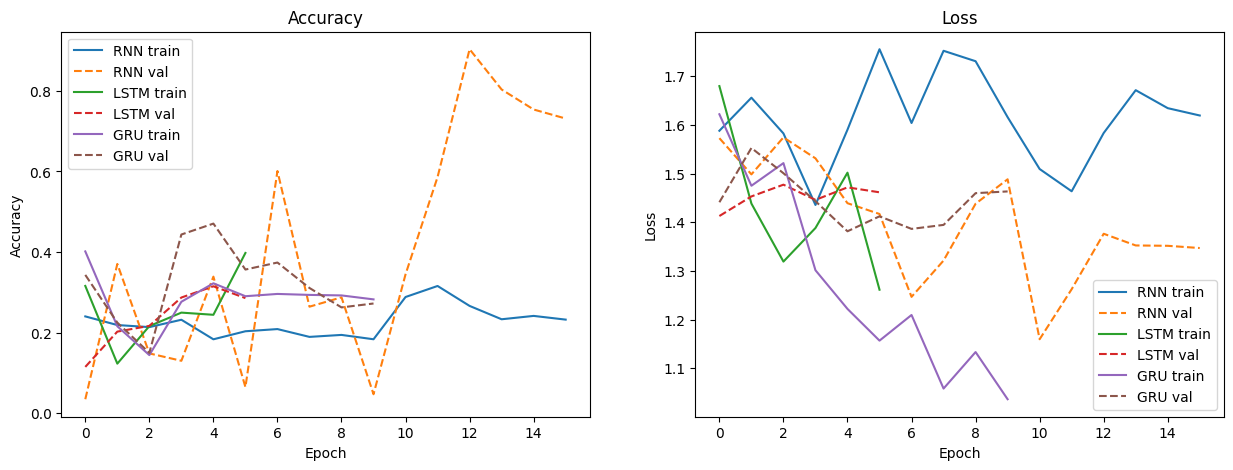

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, history in histories.items():
    axes[0].plot(history.history["accuracy"], label=f"{name} train")
    axes[0].plot(history.history["val_accuracy"], "--", label=f"{name} val")

    axes[1].plot(history.history["loss"], label=f"{name} train")
    axes[1].plot(history.history["val_loss"], "--", label=f"{name} val")

axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.show()

In [18]:
results = []
predictions = {}

for name, model in trained_models.items():
    prob = model.predict(X_test_rnn, batch_size=BATCH_SIZE, verbose=0)
    pred = np.argmax(prob, axis=1)
    predictions[name] = pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_int, pred),
        "Precision (macro)": precision_score(y_test_int, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test_int, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test_int, pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test_int, pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1 (macro)", ascending=False)
display(results_df)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
1,LSTM,0.218857,0.229431,0.224459,0.131544,0.323948
2,GRU,0.154010,0.213649,0.196361,0.100553,0.231569
0,RNN,0.101902,0.206734,0.323194,0.087338,0.136830


In [19]:
for name, pred in predictions.items():
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print(
        classification_report(
            y_test_int,
            pred,
            labels=list(range(NUM_CLASSES)),
            target_names=CLASSES,
            zero_division=0
        )
    )


RNN
              precision    recall  f1-score   support

           N       0.83      0.07      0.13     14837
           S       0.00      0.00      0.00       566
           V       0.20      0.61      0.30       983
           F       0.00      0.93      0.00        15
           Q       0.00      0.00      0.00         7

    accuracy                           0.10     16408
   macro avg       0.21      0.32      0.09     16408
weighted avg       0.76      0.10      0.14     16408


LSTM
              precision    recall  f1-score   support

           N       0.86      0.21      0.34     14837
           S       0.07      0.48      0.13       566
           V       0.21      0.17      0.19       983
           F       0.00      0.27      0.00        15
           Q       0.00      0.00      0.00         7

    accuracy                           0.22     16408
   macro avg       0.23      0.22      0.13     16408
weighted avg       0.79      0.22      0.32     16408


GRU
      

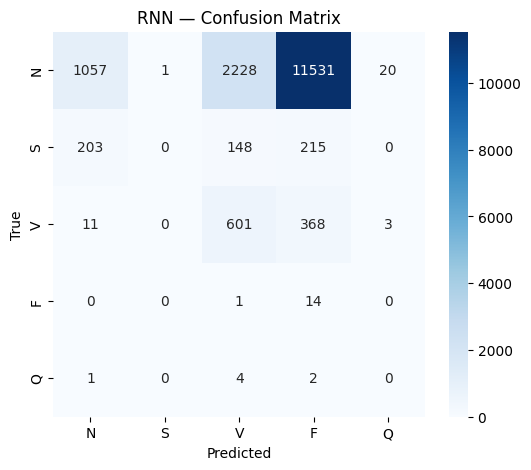

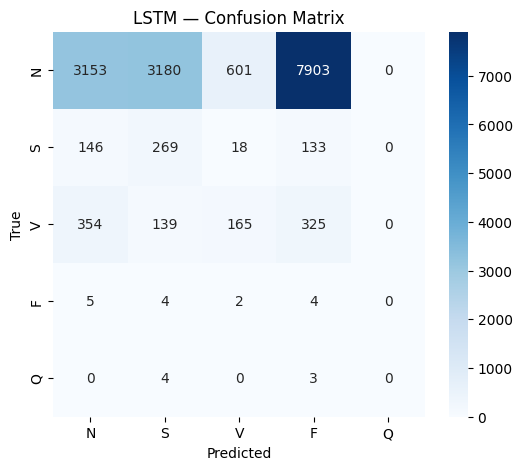

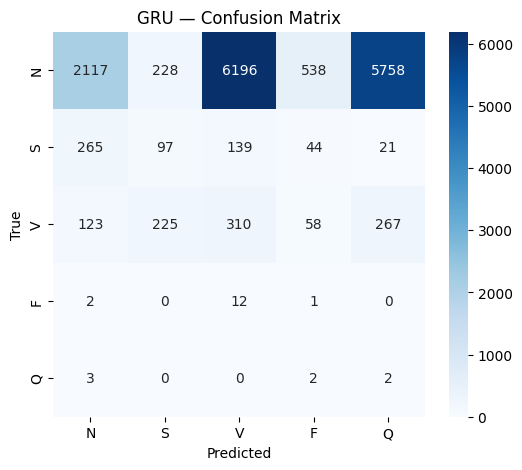

In [20]:
for name, pred in predictions.items():
    cm = confusion_matrix(
        y_test_int,
        pred,
        labels=list(range(NUM_CLASSES))
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        cmap="Blues"
    )
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"{name} — Confusion Matrix")
    plt.show()

In [21]:
comparison = results_df.set_index("Model")
display(comparison)

best_model = results_df.iloc[0]["Model"]
print(f"Best model by macro F1: {best_model}")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
Model,,,,,
LSTM,0.218857,0.229431,0.224459,0.131544,0.323948
GRU,0.154010,0.213649,0.196361,0.100553,0.231569
RNN,0.101902,0.206734,0.323194,0.087338,0.136830


Best model by macro F1: LSTM


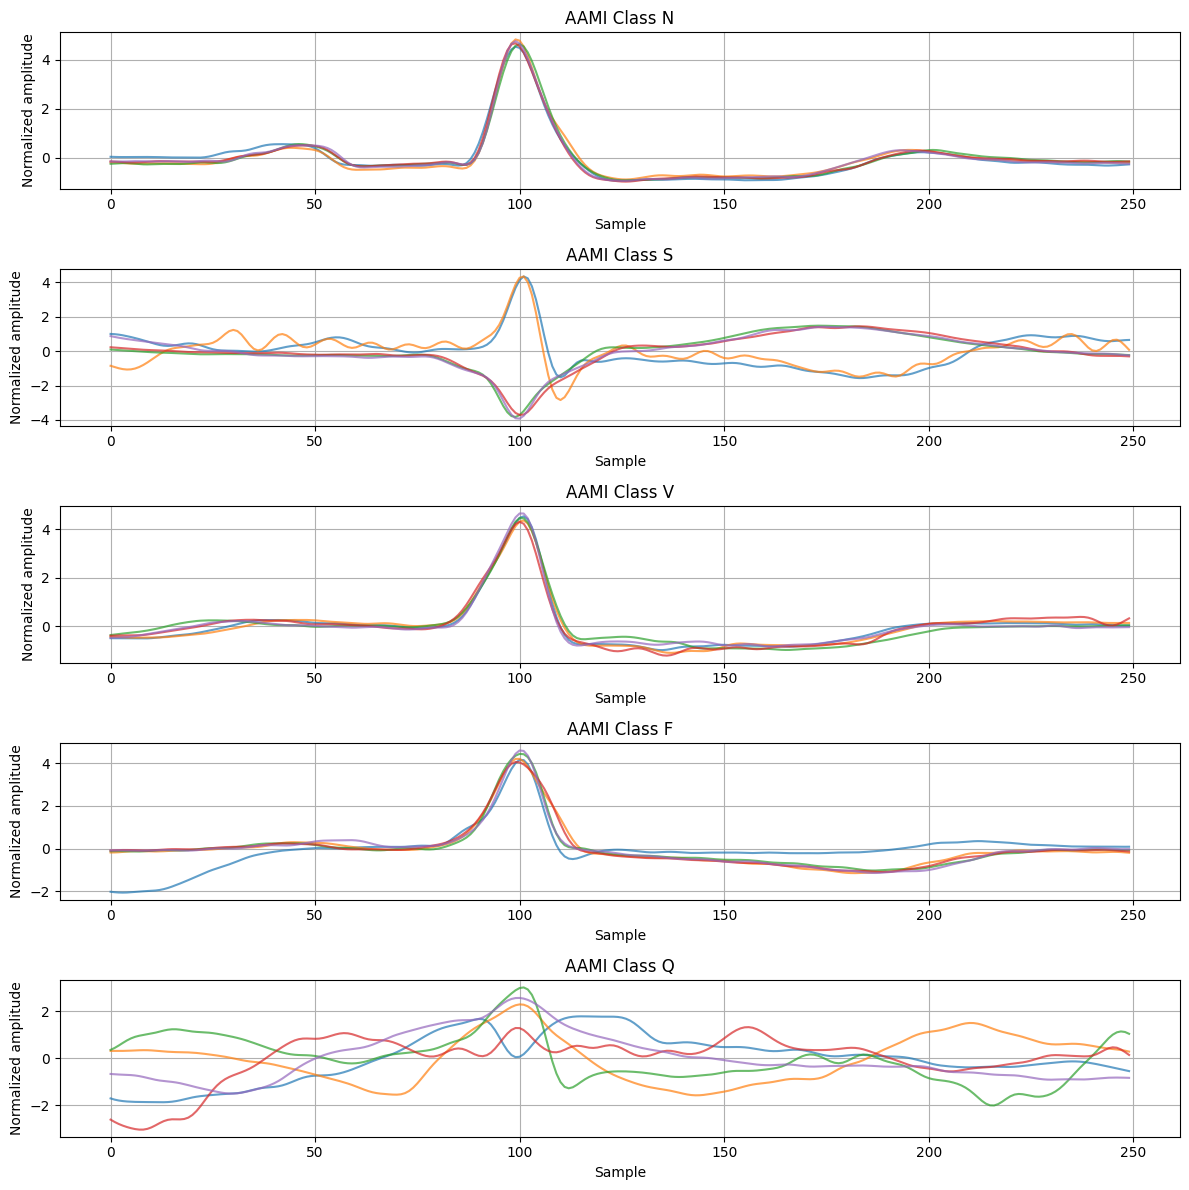

In [22]:
fig, axes = plt.subplots(len(CLASSES), 1, figsize=(12, 12))

for ax, cls in zip(axes, CLASSES):
    idx = np.where(y_test == cls)[0]

    if len(idx) == 0:
        ax.set_title(f"No {cls} examples in test set")
        continue

    for j in idx[:5]:
        ax.plot(X_test[j], alpha=0.7)

    ax.set_title(f"AAMI Class {cls}")
    ax.set_xlabel("Sample")
    ax.set_ylabel("Normalized amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()